![Banner](../../../../Images/Banner/07_remote_sensing/09_13_banner_rs_capstones.png)


# Flood Mapping with Sentinel-1 Data - Sylhet, Bangladesh

This notebook follows the UN-SPIDER recommended practice for flood extent mapping, using the local Sentinel-1 GRD products and AOI in `Data/08_remote_sensing/08_11_Capstones/Sylhet_sentinel1/`.


## Overview

The supplied sibling `flood_mapping.ipynb` is empty, so the documented [UN-SPIDER steps](https://un-spider.org/advisory-support/recommended-practices/recommended-practice-google-earth-engine-flood-mapping/step-by-step) are the workflow reference.

Unlike a synthetic demo, this workflow reads and calibrates the actual SAFE measurement subsets, co-registers the dates on a common grid, and detects change from pre- and post-flood VH backscatter composites. The available scenes are all **ascending, relative orbit 114**: May 24 and June 5, 2025 (before), July 11 and August 16, 2025 (after).

**Interpretation and limits:** The supplied folder contains no DEM, JRC permanent-water, population, or land-cover rasters. The output is therefore a radar-derived *candidate* flood extent; slope/permanent-water exclusions and exposure/damage estimates are not made. Flood detections can include seasonal or permanent water and other surface changes.


## Setup and input locations

**Installation.** This notebook needs installation option 5 (core, spatial analysis, spatial statistics, geostatistics and remote sensing): `pip install "geolattice[remote-sensing]"`. See "Installation options" in the GeoLattice README.

In [1]:
# Setup. Libraries, local ../../../../Data/08_remote_sensing/08_11_Capstones/output paths, and the geolattice.rsense backend.

# 1. Silence a harmless rasterio/xarray warning that ordinary reads trigger.
import warnings
warnings.filterwarnings("ignore", category=UserWarning)

# 2. Standard library helpers: datetime parsing, filesystem paths, and SAFE-manifest XML.
from datetime import datetime
from pathlib import Path
import xml.etree.ElementTree as ET

# 3. Vector, raster, and plotting libraries used throughout the notebook.
import geopandas as gpd
import leafmap
import matplotlib.pyplot as plt
import numpy as np
import rasterio
from rasterio.features import geometry_mask
import xarray as xr
from shapely.geometry import mapping

# 4. geolattice.rsense is the remote-sensing toolkit used across this series; read_safe parses
#    a Sentinel-1 .SAFE product's manifest and locates its measurement/calibration/noise files.
import geolattice.rsense as rs
from geolattice.rsense.core.io import read_safe

# 5. Plot resolution for every figure below, and the compute backend geolattice.rsense uses.
plt.rcParams.update({"figure.dpi": 120})
rs.set_backend("cpu")

# 6. The supplied Sentinel-1 SAFE products and AOI live under ../../../../Data/08_remote_sensing/08_11_Capstones/Sylhet_sentinel1;
#    outputs are written to an "output" subfolder created here if missing.
DATA_DIR = Path("../../../../Data/08_remote_sensing/08_11_Capstones/Sylhet_sentinel1")
if not DATA_DIR.is_dir():
    raise FileNotFoundError(f"Run this notebook from the Capstones folder; missing {DATA_DIR}")
AOI_PATH = DATA_DIR / "sylhet_aoi.geojson"
OUTPUT_DIR = DATA_DIR / "output"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
print("GeoLattice rsense:", rs.__version__)
print("Data:", DATA_DIR.resolve())

GeoLattice rsense: 0.2.0.dev0
Data: /media/zia207/SSD/GitHub/GeoLattice/Tutorials/notebooks/09_remote_sensing/09_11_Capstones/data/Sylhet_sentinel1


## Define the study area with Leafmap

The supplied GeoJSON is loaded as the default study area and displayed on an interactive Leafmap satellite basemap. Use the map's drawing toolbar to create a polygon or rectangle for a different area. After drawing, run the next cell to use your drawn geometry for this analysis; if no drawing is present, the supplied GeoJSON remains the AOI.


In [2]:
# Load the supplied AOI and draw it on an interactive Leafmap satellite basemap.

# 1. Read the GeoJSON and reproject to WGS84 so its bounds can center the map.
aoi_file = gpd.read_file(AOI_PATH)
if aoi_file.empty or aoi_file.crs is None:
    raise ValueError(f"AOI must contain geometry and a CRS: {AOI_PATH}")
aoi_file = aoi_file.to_crs("EPSG:4326")
west, south, east, north = aoi_file.total_bounds
center = ((south + north) / 2, (west + east) / 2)

# 2. Build the map centered on the AOI, with an Esri imagery basemap and the AOI outline
#    drawn in red. The map also exposes a drawing toolbar for an alternative AOI (next cell).
aoi_map = leafmap.Map(center=center, zoom=10, height="600px")
aoi_map.add_basemap("Esri.WorldImagery")
aoi_map.add_geojson(
    str(AOI_PATH),
    layer_name="Supplied Sylhet AOI",
    style={"color": "#ff3b30", "weight": 3, "fillColor": "#ff3b30", "fillOpacity": 0.12},
    hover_style={"color": "#ffff00", "weight": 4, "fillOpacity": 0.2},
    zoom_to_layer=True,
)
aoi_map.add_layer_control()
aoi_map

Map(center=[np.float64(25.0021), np.float64(91.1467)], controls=(ZoomControl(options=['position', 'zoom_in_tex…

### Use the mapped study area

If you drew a new polygon or rectangle above, use **Run** on this cell after drawing; the new Leafmap geometry will replace the default GeoJSON AOI for all subsequent processing. Otherwise, the notebook uses `sylhet_aoi.geojson`.


In [3]:
# Decide which AOI geometry to use: a hand-drawn polygon, if present, otherwise the supplied GeoJSON.

# 1. Leafmap records any polygons/rectangles drawn on the map above in draw_features.
drawn_features = aoi_map.draw_features
if drawn_features:
    # 2. Keep only polygonal drawings (ignore points/lines) and use them as the AOI.
    drawn_aoi = gpd.GeoDataFrame.from_features(drawn_features, crs="EPSG:4326")
    drawn_aoi = drawn_aoi.loc[drawn_aoi.geometry.geom_type.isin(["Polygon", "MultiPolygon"])]
    if drawn_aoi.empty:
        raise ValueError("Leafmap drawings contain no polygon geometry; draw a polygon or rectangle.")
    aoi = drawn_aoi
    aoi_source = "Leafmap drawing"
else:
    # 3. No drawing was made: fall back to the supplied sylhet_aoi.geojson loaded above.
    aoi = aoi_file.copy()
    aoi_source = str(AOI_PATH)

# 4. AOI_BOUNDS (west, south, east, north) in EPSG:4326 drives the scene window read later.
AOI_BOUNDS = tuple(float(v) for v in aoi.total_bounds)
print("Study area source:", aoi_source)
print("CRS:", aoi.crs)
print("Bounds (west, south, east, north):", AOI_BOUNDS)
print(f"AOI polygon feature(s): {len(aoi)}")

Study area source: data/Sylhet_sentinel1/sylhet_aoi.geojson
CRS: EPSG:4326
Bounds (west, south, east, north): (90.9146, 24.8129, 91.3788, 25.1913)
AOI polygon feature(s): 1


## Set dates and Sentinel-1 parameters

Use date windows rather than one acquisition, the same polarization and pass, and the same relative orbit for both periods. Metadata in the local SAFE manifests is checked below. A 30 m common grid keeps this local workflow manageable while retaining the broad flood signal.


In [4]:
# Analysis parameters: date windows, polarization/orbit filters, grid, and detection thresholds.

# 1. Pre- and post-flood date windows. Using a window rather than one date lets step 3 pick
#    every matching local scene, which are then median-composited in step 5 to reduce speckle.
BEFORE = ("2025-05-01", "2025-06-30")
AFTER = ("2025-07-01", "2025-08-31")

# 2. Keep one polarization, pass direction, and relative orbit so every scene compared
#    shares the same viewing geometry; mixing orbits/passes would look like spurious change.
POLARIZATION = "VH"
PASS_DIRECTION = "ASCENDING"
RELATIVE_ORBIT = 114

# 3. Common analysis grid: UTM zone 46N (covers Sylhet) resampled to 30 m pixels.
GRID_CRS = "EPSG:32646"
RESOLUTION_M = 30.0

# 4. Flood-detection tuning: a post/pre backscatter ratio below 0.80 (a >=20% drop in linear
#    sigma-nought) flags candidate new water; a 3x3 median filter suppresses speckle first;
#    detected blobs smaller than 8 pixels are discarded as noise.
RATIO_THRESHOLD = 0.80  # new-water post/pre linear backscatter ratio
SMOOTH_SIZE = 3         # median-filter window in pixels
MIN_PIXELS = 8          # remove isolated detections smaller than this component size
print(f"Before {BEFORE[0]} to {BEFORE[1]}; after {AFTER[0]} to {AFTER[1]}")
print(f"{POLARIZATION}, {PASS_DIRECTION} relative orbit {RELATIVE_ORBIT}; {RESOLUTION_M:g} m grid")

Before 2025-05-01 to 2025-06-30; after 2025-07-01 to 2025-08-31
VH, ASCENDING relative orbit 114; 30 m grid


## Inventory and filter the local scenes

Read pass direction and relative orbit from each `manifest.safe`, then retain only scenes inside the selected date periods with the requested polarization and orbit. This avoids comparing different viewing geometries.


In [5]:
# Catalogue every local SAFE product, then keep only the ones matching the chosen orbit,
# pass direction, polarization, and date windows.

# 1. Parse one SAFE product's manifest.safe for its pass direction (ascending/descending)
#    and relative orbit number, by walking the XML tree for the matching tags.
def manifest_metadata(safe_path):
    root = ET.parse(safe_path / "manifest.safe").getroot()
    pass_direction, relative_orbit = None, None
    for element in root.iter():
        tag = element.tag.rsplit("}", 1)[-1]
        if tag == "pass" and element.text:
            pass_direction = element.text.strip().upper()
        elif tag == "relativeOrbitNumber" and element.attrib.get("type") == "start":
            relative_orbit = int(element.text)
    if pass_direction is None or relative_orbit is None:
        raise ValueError(f"Could not read pass/orbit metadata from {safe_path / 'manifest.safe'}")
    return pass_direction, relative_orbit

# 2. Build a catalogue of every *.SAFE folder in DATA_DIR: acquisition date (parsed from the
#    SAFE filename), pass/orbit (from the manifest), available polarizations, and the
#    read_safe() handle used later to locate each band's measurement/calibration/noise files.
scene_catalog = []
for safe_path in sorted(DATA_DIR.glob("*.SAFE")):
    scene_date = datetime.strptime(safe_path.name.split("_")[5][:8], "%Y%m%d").date()
    info = read_safe(safe_path)
    pass_direction, relative_orbit = manifest_metadata(safe_path)
    polarizations = tuple(sorted(p.upper() for p in info["measurement"]))
    scene_catalog.append({
        "path": safe_path,
        "date": scene_date,
        "pass": pass_direction,
        "relative_orbit": relative_orbit,
        "polarizations": polarizations,
        "info": info,
    })

# 3. Display the full catalogue as a table before filtering, for a visual sanity check.
catalog = gpd.pd.DataFrame([
    {"date": s["date"].isoformat(), "pass": s["pass"],
     "relative orbit": s["relative_orbit"], "polarizations": ", ".join(s["polarizations"]),
     "SAFE": s["path"].name}
    for s in scene_catalog
])
display(catalog)

# 4. Keep scenes that match the chosen pass direction, relative orbit, and polarization, and
#    fall inside either the BEFORE or AFTER date window; split the result into pre/post lists.
before_start, before_end = (datetime.strptime(d, "%Y-%m-%d").date() for d in BEFORE)
after_start, after_end = (datetime.strptime(d, "%Y-%m-%d").date() for d in AFTER)
selected = [
    s for s in scene_catalog
    if s["pass"] == PASS_DIRECTION
    and s["relative_orbit"] == RELATIVE_ORBIT
    and POLARIZATION in s["polarizations"]
    and (before_start <= s["date"] <= before_end or after_start <= s["date"] <= after_end)
]
pre_scenes = [s for s in selected if before_start <= s["date"] <= before_end]
post_scenes = [s for s in selected if after_start <= s["date"] <= after_end]
if not pre_scenes or not post_scenes:
    raise ValueError(f"Need scenes in both periods; found {len(pre_scenes)} pre and {len(post_scenes)} post")
print(f"Selected {len(pre_scenes)} pre-flood and {len(post_scenes)} post-flood scenes.")
for item in selected:
    print(item["date"], item["pass"], f"relative orbit {item['relative_orbit']}", item["path"].name)

,date,pass,relative orbit,polarizations,SAFE
0,2025-05-24,ASCENDING,114,"VH, VV",S1A_IW_GRDH_1SDV_20250524T120501_20250524T1205...
1,2025-06-05,ASCENDING,114,"VH, VV",S1A_IW_GRDH_1SDV_20250605T120500_20250605T1205...
2,2025-07-11,ASCENDING,114,"VH, VV",S1A_IW_GRDH_1SDV_20250711T120458_20250711T1205...
3,2025-08-16,ASCENDING,114,"VH, VV",S1A_IW_GRDH_1SDV_20250816T120458_20250816T1205...


Selected 2 pre-flood and 2 post-flood scenes.
2025-05-24 ASCENDING relative orbit 114 S1A_IW_GRDH_1SDV_20250524T120501_20250524T120526_059336_075D43_D7CC.SAFE
2025-06-05 ASCENDING relative orbit 114 S1A_IW_GRDH_1SDV_20250605T120500_20250605T120525_059511_076353_BC8B.SAFE
2025-07-11 ASCENDING relative orbit 114 S1A_IW_GRDH_1SDV_20250711T120458_20250711T120523_060036_07756C_B448.SAFE
2025-08-16 ASCENDING relative orbit 114 S1A_IW_GRDH_1SDV_20250816T120458_20250816T120523_060561_07883A_6F5E.SAFE


## Calibrate, subset, and co-register the GRD scenes

`read_grd_subset` reads only the AOI window from each large measurement GeoTIFF, applies the SAFE calibration/noise LUTs, and zeros border noise. `create_stack` geocodes each window onto one shared UTM grid using its geolocation control points. Values remain in linear sigma-nought units for physically meaningful temporal ratios.


In [6]:
# Read, calibrate, and co-register each selected scene onto one common UTM grid.

# 1. For every selected scene, read only the AOI window (plus a 100 m margin) from the VH
#    measurement GeoTIFF, applying the SAFE calibration/noise LUTs to produce calibrated
#    sigma-nought backscatter and zeroing out border-noise artifacts near the swath edges.
subsets, scene_times = [], []
for scene in selected:
    info = scene["info"]
    pol = POLARIZATION.lower()
    subset = rs.sar.read_grd_subset(
        info["measurement"][pol],
        info["calibration"][pol],
        info["noise"][pol],
        bounds=AOI_BOUNDS,
        margin=100,
        kind="sigmaNought",
        border_noise=True,
    )
    subsets.append(subset)
    scene_times.append(np.datetime64(scene["date"].isoformat()))
    print(f"{scene['date']}: read window {subset['window']}, {subset['data'].shape}, {len(subset['gcps'])} local GCPs")

# 2. Geocode every scene's window onto one shared grid (GRID_CRS, RESOLUTION_M) using its
#    ground control points, stacking the results along a time dimension. This turns scenes
#    read from different raw pixel grids into pixel-for-pixel comparable arrays.
stack = rs.sar.create_stack(
    subsets,
    scene_times,
    bounds=AOI_BOUNDS,
    crs=GRID_CRS,
    resolution=RESOLUTION_M,
    resampling="bilinear",
    name=f"{POLARIZATION.lower()}_sigma0",
)
# 3. Report the stack shape and how much of the grid's bounding box each date actually covers.
scene_coverage = np.isfinite(stack.values).mean(axis=(1, 2))
print("Common stack shape:", stack.shape)
for date, coverage in zip(stack.time.values, scene_coverage):
    print(f"{np.datetime_as_string(date, unit='D')}: {coverage:.1%} valid coverage of grid bounding box")

2025-05-24: read window (7247, 20029, 5099, 5571), (5099, 5571), 30 local GCPs


2025-06-05: read window (7248, 20026, 5099, 5571), (5099, 5571), 30 local GCPs


2025-07-11: read window (7247, 20021, 5099, 5572), (5099, 5572), 30 local GCPs


2025-08-16: read window (7242, 20041, 5100, 5572), (5100, 5572), 30 local GCPs


Common stack shape: (4, 1420, 1582)
2025-05-24: 99.0% valid coverage of grid bounding box
2025-06-05: 99.0% valid coverage of grid bounding box
2025-07-11: 99.0% valid coverage of grid bounding box
2025-08-16: 98.9% valid coverage of grid bounding box


## Build the before/after composites and mask to the AOI

A temporal median reduces single-date speckle and transient noise. The 3×3 median filter is then applied by GeoLattice as part of the UN-SPIDER workflow. The AOI polygon is rasterized on the common grid, so pixels outside the supplied boundary do not contribute to detections or area statistics.


In [7]:
# Build the pre-/post-flood composites and mask both to the AOI polygon.

# 1. Temporal median across each period's dates reduces speckle and transient noise that a
#    single scene would carry; stack.sel(...) picks only that period's time slices first.
pre_times = [np.datetime64(s["date"].isoformat()) for s in pre_scenes]
post_times = [np.datetime64(s["date"].isoformat()) for s in post_scenes]
before = stack.sel(time=pre_times).median(dim="time", skipna=True).rename("before_vh_sigma0")
after = stack.sel(time=post_times).median(dim="time", skipna=True).rename("after_vh_sigma0")

# 2. Rasterize the AOI polygon onto the common grid: True inside the AOI, False outside.
#    geometry_mask with invert=True marks pixels covered by the polygon as True.
aoi_projected = aoi.to_crs(GRID_CRS)
aoi_inside = geometry_mask(
    [mapping(geom) for geom in aoi_projected.geometry],
    out_shape=(stack.sizes["y"], stack.sizes["x"]),
    transform=stack.rio.transform(),
    invert=True,
    all_touched=False,
)
# 3. Wrap that boolean grid as a georeferenced DataArray and use it to null out pixels
#    outside the AOI in both composites, so later statistics only count AOI pixels.
aoi_mask = xr.DataArray(
    aoi_inside, dims=("y", "x"), coords={"y": stack.y, "x": stack.x}, name="aoi_mask"
).rio.write_crs(GRID_CRS).rio.write_transform(stack.rio.transform())
before = before.where(aoi_mask)
after = after.where(aoi_mask)

# 4. valid_data flags pixels that are inside the AOI AND have a finite value in both
#    composites; it is reused throughout to keep area statistics and exports consistent.
valid_data = np.isfinite(before.values) & np.isfinite(after.values) & aoi_inside
print(f"AOI pixels: {int(aoi_inside.sum()):,}")
print(f"AOI pixels with both period composites: {int(valid_data.sum()):,} ({valid_data.sum()/aoi_inside.sum():.1%})")

AOI pixels: 2,180,245
AOI pixels with both period composites: 2,161,618 (99.1%)


## Inspect the radar composites

The maps are calibrated VH sigma-nought displayed in dB. Compare the pre- and post-flood composites before applying the ratio threshold; water commonly appears darker, but vegetation, soil moisture, and acquisition conditions can also change the signal.


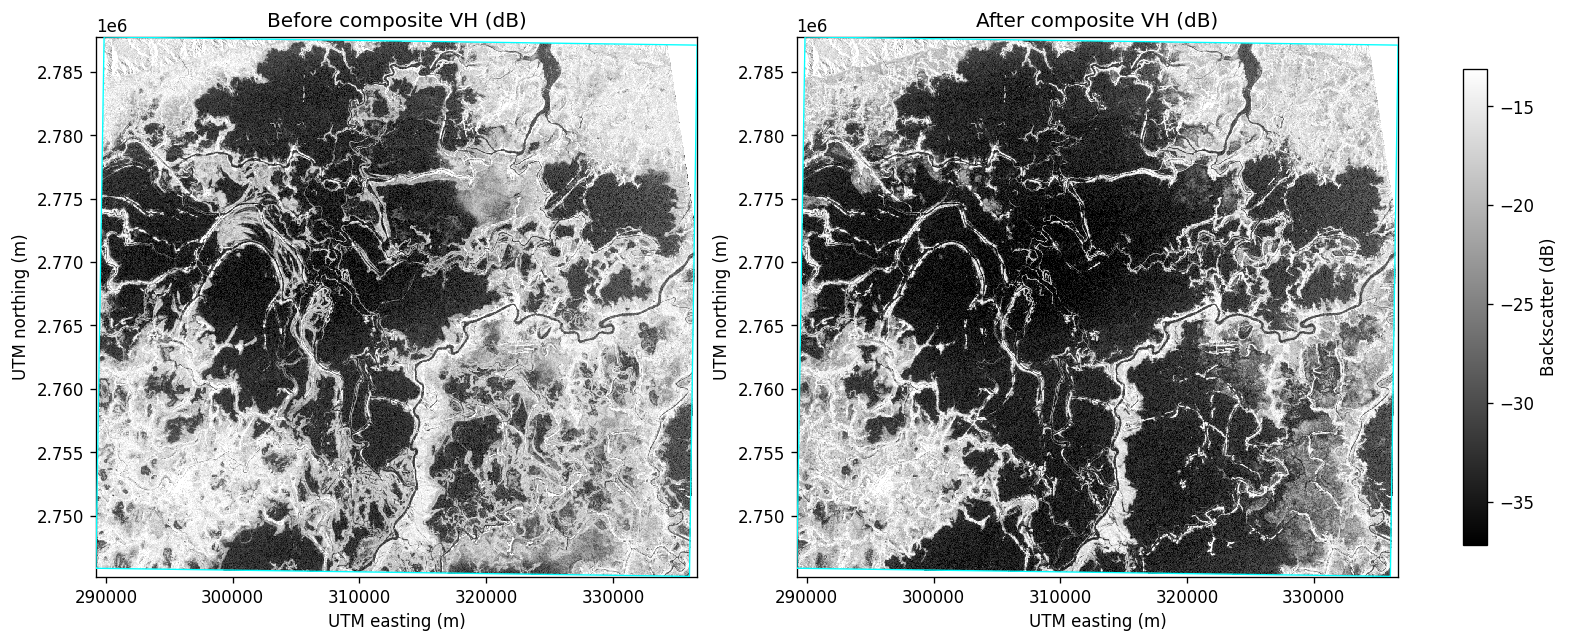

In [8]:
# Convert both composites to dB and plot them side by side for a visual before/after check.

# 1. rs.sar.to_db converts linear sigma-nought to decibels (10*log10); the AOI mask keeps
#    pixels outside the study area as NaN so they do not affect the color stretch below.
before_db = rs.sar.to_db(before).where(aoi_mask)
after_db = rs.sar.to_db(after).where(aoi_mask)

# 2. A shared 2nd-98th percentile stretch (computed from both dates' valid pixels) keeps the
#    before/after panels on the same grayscale scale, so darker really means lower backscatter
#    in both images rather than an artifact of two different per-image stretches.
valid_db = np.concatenate([
    before_db.values[np.isfinite(before_db.values)],
    after_db.values[np.isfinite(after_db.values)],
])
vmin, vmax = np.percentile(valid_db, [2, 98])

# imshow defaults to pixel coordinates; use the raster's UTM transform so the
# GeoDataFrame AOI boundary and SAR pixels are drawn in the same map coordinates.
transform = stack.rio.transform()
MAP_EXTENT = (
    transform.c,
    transform.c + transform.a * stack.sizes["x"],
    transform.f + transform.e * stack.sizes["y"],
    transform.f,
)

# 3. Shared helper for every map panel in this notebook: draws a raster in true map
#    coordinates (via MAP_EXTENT) and overlays the AOI boundary in cyan on top of it.
def show_map_image(ax, values, *, cmap, vmin=None, vmax=None, alpha=1.0):
    image = ax.imshow(
        np.ma.masked_invalid(values),
        extent=MAP_EXTENT,
        origin="upper",
        interpolation="nearest",
        cmap=cmap,
        vmin=vmin,
        vmax=vmax,
        alpha=alpha,
    )
    aoi_projected.boundary.plot(ax=ax, color="cyan", linewidth=0.8, zorder=4)
    ax.set_xlim(MAP_EXTENT[0], MAP_EXTENT[1])
    ax.set_ylim(MAP_EXTENT[2], MAP_EXTENT[3])
    ax.set_aspect("equal")
    ax.set_xlabel("UTM easting (m)")
    ax.set_ylabel("UTM northing (m)")
    return image

# 4. Draw the before/after dB composites side by side with one shared colorbar.
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5), constrained_layout=True)
for ax, image, title in zip(
    axes,
    [before_db, after_db],
    ["Before composite VH (dB)", "After composite VH (dB)"],
):
    view = show_map_image(ax, image.values, cmap="gray", vmin=vmin, vmax=vmax)
    ax.set_title(title)
fig.colorbar(view, ax=axes, shrink=0.78, label="Backscatter (dB)")
plt.show()

## Detect new water with the backscatter ratio

The GeoLattice `un_spider_flood_mapping` implementation converts linear backscatter to a post/pre linear ratio, applies a 3×3 median filter, and identifies new-water candidates below **0.80** (at least a 20% decrease). It also removes connected components smaller than eight pixels. No permanent-water or slope mask is passed because those source rasters are not present locally.


In [9]:
# Detect candidate new-water pixels from the post/pre linear backscatter ratio.

# 1. un_spider_flood_mapping implements the UN-SPIDER recipe: compute the post/pre ratio in
#    linear units, apply a 3x3 median filter (SMOOTH_SIZE) to suppress speckle, flag pixels
#    whose ratio falls below RATIO_THRESHOLD as candidate new water, and drop connected
#    components smaller than MIN_PIXELS as likely noise rather than real flood patches.
flood_result = rs.sar.un_spider_flood_mapping(
    before,
    after,
    units="linear",
    ratio_threshold=RATIO_THRESHOLD,
    smooth_size=SMOOTH_SIZE,
    min_pixels=MIN_PIXELS,
)
# 2. Clip the ratio to the AOI, and intersect the flood mask with valid_data so neither
#    out-of-AOI pixels nor pixels missing from either composite are counted as flood.
ratio = flood_result["ratio"].where(aoi_mask).rename("post_pre_sigma0_ratio")
flood_values = np.asarray(flood_result["flood"].values, dtype=bool) & valid_data
flood = flood_result["flood"].copy(data=flood_values).rename("candidate_flood")

# 3. Convert the flagged pixel count to hectares using the grid's pixel area, and report it.
pixel_area_m2 = abs(float(stack.rio.transform().a * stack.rio.transform().e))
flood_pixels = int(flood_values.sum())
flood_area_ha = flood_pixels * pixel_area_m2 / 10_000
print(f"Ratio threshold: post/pre < {RATIO_THRESHOLD:.2f}")
print(f"Candidate flood pixels: {flood_pixels:,}")
print(f"Candidate flood area: {flood_area_ha:,.1f} ha")
print("Note: candidate extent is not corrected for permanent water or terrain slope.")

Ratio threshold: post/pre < 0.80
Candidate flood pixels: 1,303,451
Candidate flood area: 117,310.6 ha
Note: candidate extent is not corrected for permanent water or terrain slope.


## Visualize the candidate flood map


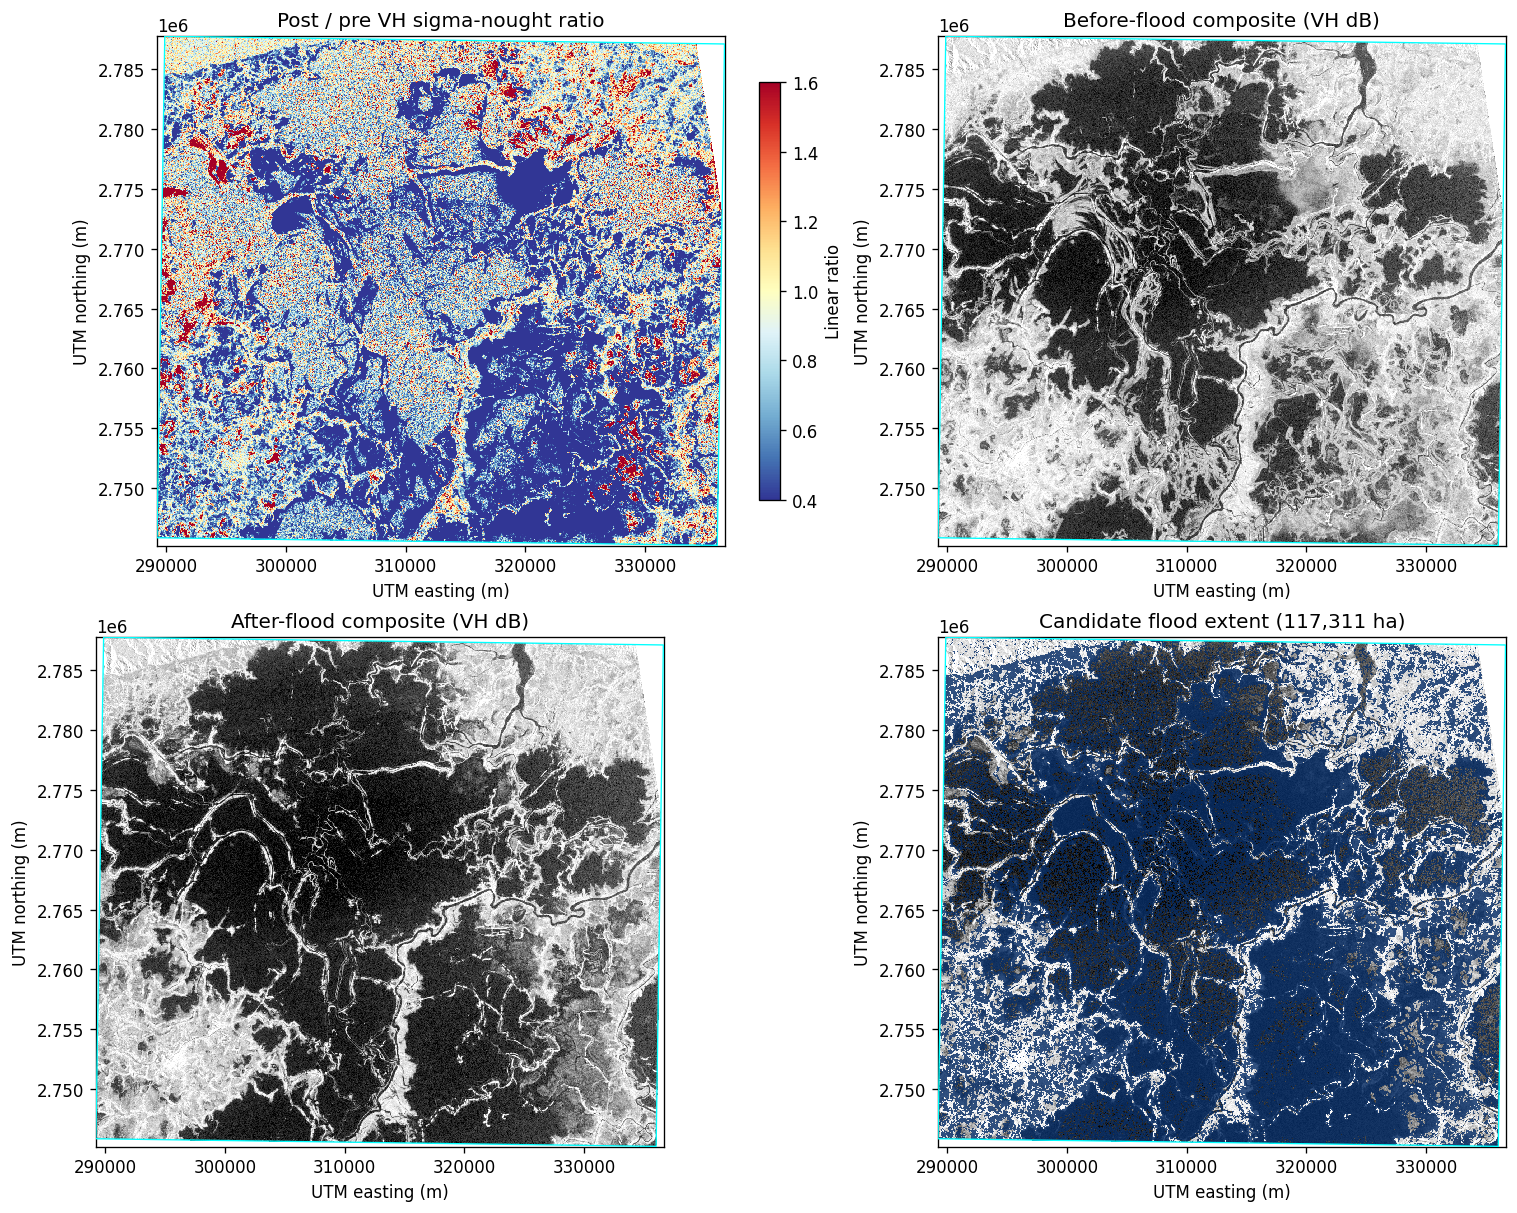

In [10]:
# Four-panel summary: the ratio map, both dB composites, and the candidate flood overlay.

# 1. Top-left: the post/pre linear ratio itself, so low-ratio (likely new water) areas are
#    visible directly, not just after thresholding.
fig, axes = plt.subplots(2, 2, figsize=(13, 10), constrained_layout=True)
ratio_view = show_map_image(
    axes[0, 0], ratio.values, cmap="RdYlBu_r", vmin=0.4, vmax=1.6,
)
axes[0, 0].set_title("Post / pre VH sigma-nought ratio")
fig.colorbar(ratio_view, ax=axes[0, 0], shrink=0.82, label="Linear ratio")

# 2. Top-right and bottom-left: the before/after dB composites again, for direct comparison
#    against the ratio and the final flood mask within the same figure.
show_map_image(axes[0, 1], before_db.values, cmap="gray", vmin=vmin, vmax=vmax)
axes[0, 1].set_title("Before-flood composite (VH dB)")
show_map_image(axes[1, 0], after_db.values, cmap="gray", vmin=vmin, vmax=vmax)
axes[1, 0].set_title("After-flood composite (VH dB)")

# 3. Bottom-right: the after-flood composite with the candidate flood mask overlaid in blue,
#    using a masked array so only flagged pixels draw (everywhere else stays transparent).
show_map_image(axes[1, 1], after_db.values, cmap="gray", vmin=vmin, vmax=vmax)
flood_layer = np.ma.masked_where(~flood_values, flood_values.astype(float))
axes[1, 1].imshow(
    flood_layer,
    extent=MAP_EXTENT,
    origin="upper",
    interpolation="nearest",
    cmap="Blues",
    vmin=0,
    vmax=1,
    alpha=0.8,
)
axes[1, 1].set_xlim(MAP_EXTENT[0], MAP_EXTENT[1])
axes[1, 1].set_ylim(MAP_EXTENT[2], MAP_EXTENT[3])
axes[1, 1].set_aspect("equal")
axes[1, 1].set_title(f"Candidate flood extent ({flood_area_ha:,.0f} ha)")
plt.show()

## Damage assessment data availability

The reference practice also overlays a permanent-water mask, terrain slope, population, and land-cover classes to refine flood extent and estimate exposed people, cropland, and urban area. None of those auxiliary rasters is included in `Data/08_remote_sensing/08_11_Capstones/Sylhet_sentinel1/`; do not interpret a radar-only candidate extent as a validated damage or exposure estimate. Add co-registered local rasters before calculating those measures.


## Export raster and vector products

Write the radar-derived flood candidate, post/pre ratio, and the two smoothed dB composites as COGs. The flood raster uses 255 as NoData outside the AOI or where either period lacks valid data. Polygon output is generated from the same clipped candidate mask.


In [11]:
# Export the raster and vector flood products as Cloud-Optimized GeoTIFFs and a GeoPackage.

# 1. The flood mask, as uint8 (0/1), with 255 marking NoData outside the AOI or wherever
#    either period lacked a valid composite value (per valid_data from step 5).
flood_raster = flood.astype("uint8").where(xr.DataArray(valid_data, dims=("y", "x"), coords={"y": stack.y, "x": stack.x}), 255)
flood_raster = flood_raster.rio.write_crs(GRID_CRS).rio.write_transform(stack.rio.transform()).rio.write_nodata(255)
ratio_export = ratio.where(xr.DataArray(valid_data, dims=("y", "x"), coords={"y": stack.y, "x": stack.x}))

# 2. The smoothed before/after composites (post-median-filter, as used for detection) in dB,
#    with a float NoData sentinel (-9999) marking AOI/coverage gaps for the ratio and dB rasters.
before_export = rs.sar.to_db(flood_result["pre_smoothed"]).where(aoi_mask).rename("before_vh_db")
after_export = rs.sar.to_db(flood_result["post_smoothed"]).where(aoi_mask).rename("after_vh_db")
FLOAT_NODATA = -9999.0
ratio_export = ratio_export.fillna(FLOAT_NODATA).rio.write_nodata(FLOAT_NODATA, encoded=True)
before_export = before_export.fillna(FLOAT_NODATA).rio.write_nodata(FLOAT_NODATA, encoded=True)
after_export = after_export.fillna(FLOAT_NODATA).rio.write_nodata(FLOAT_NODATA, encoded=True)

# 3. Write all four rasters as COGs under OUTPUT_DIR.
rs.write(flood_raster.rename("candidate_flood"), OUTPUT_DIR / "sylhet_flood_extent.tif", nodata=255)
rs.write(ratio_export.rename("post_pre_sigma0_ratio"), OUTPUT_DIR / "sylhet_post_pre_ratio.tif", nodata=FLOAT_NODATA)
rs.write(before_export, OUTPUT_DIR / "sylhet_before_vh_db.tif", nodata=FLOAT_NODATA)
rs.write(after_export, OUTPUT_DIR / "sylhet_after_vh_db.tif", nodata=FLOAT_NODATA)

# 4. Vectorize the flood mask into polygons (dropping fragments under MIN_PIXELS again) and
#    write them as a GeoPackage, then report every file written and its size.
flood_vector = rs.sar.mask_to_polygons(flood, min_pixels=MIN_PIXELS)
if flood_vector.empty:
    raise RuntimeError("No flood polygons were produced; check scene coverage and threshold.")
flood_vector.to_file(OUTPUT_DIR / "sylhet_flood_extent.gpkg", driver="GPKG")
exported_paths = [
    OUTPUT_DIR / "sylhet_flood_extent.tif",
    OUTPUT_DIR / "sylhet_post_pre_ratio.tif",
    OUTPUT_DIR / "sylhet_before_vh_db.tif",
    OUTPUT_DIR / "sylhet_after_vh_db.tif",
    OUTPUT_DIR / "sylhet_flood_extent.gpkg",
]
print("Wrote:")
for output_path in exported_paths:
    print(f"  {output_path.name}: {output_path.stat().st_size:,} bytes")
print(f"Flood polygons: {len(flood_vector):,}")

Wrote:
  sylhet_flood_extent.tif: 310,232 bytes
  sylhet_post_pre_ratio.tif: 20,627,921 bytes
  sylhet_before_vh_db.tif: 15,589,845 bytes
  sylhet_after_vh_db.tif: 15,438,691 bytes
  sylhet_flood_extent.gpkg: 7,200,768 bytes
Flood polygons: 2,800


## Results and limitations

This analysis uses calibrated Sentinel-1A VH GRD acquisitions on a common grid and the provided Sylhet AOI. The exported map is a **candidate flood extent**, not a validated final map. Before operational interpretation, use locally co-registered JRC permanent-water and DEM slope masks, review the result against reference imagery or field data, and provide population/land-cover rasters for exposure estimates. The UN-SPIDER practice also warns about false positives from non-flood surface change, missed inundation under dense vegetation or urban structures, and the coarse resolution of auxiliary datasets.


## Final candidate flood extent map

The complete candidate flood mask is overlaid on the post-flood VH composite. This map is embedded as a standard notebook image so it remains visible in the standalone HTML report, without relying on browser support for interactive widget frames. The AOI boundary is shown in cyan; candidate flood pixels are red.


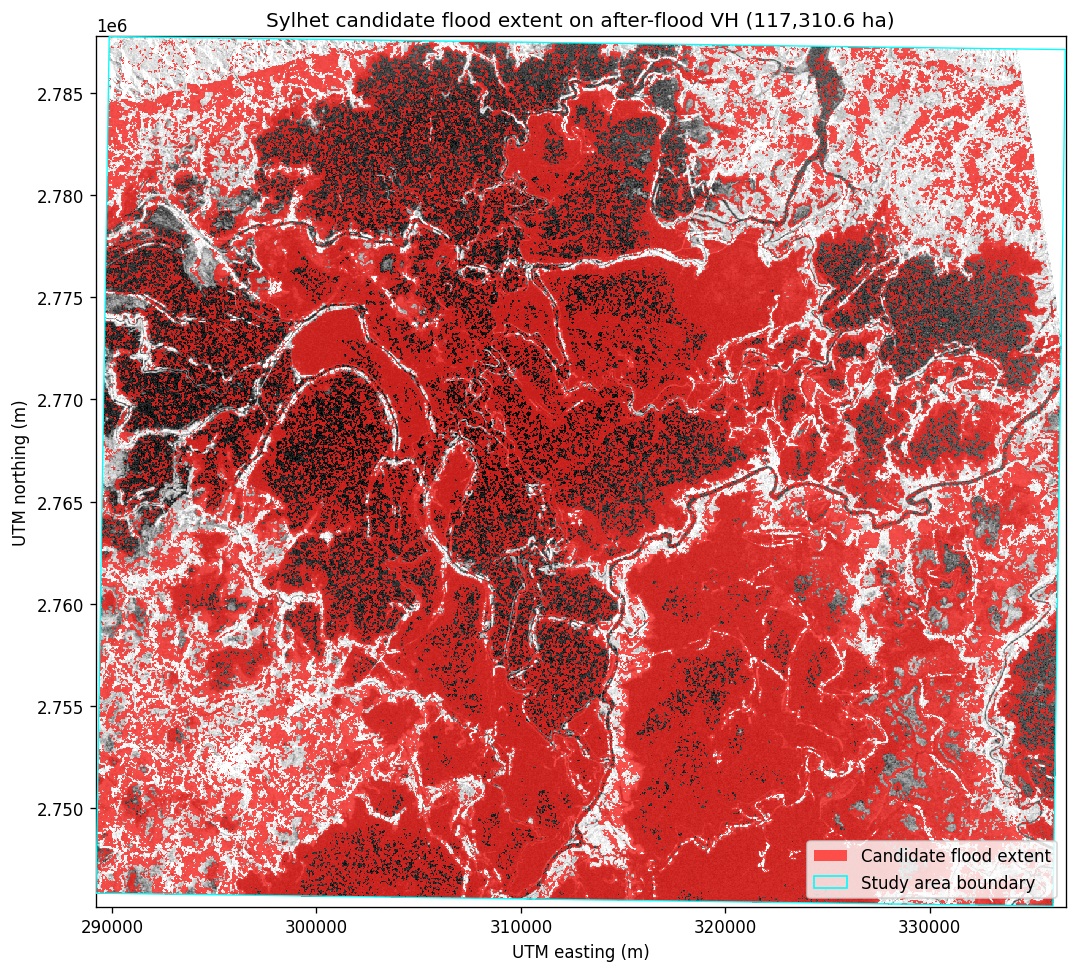

Displaying all 1,303,451 candidate flood pixels across 2,800 polygons
Candidate extent: 117,310.6 ha (1,173.1 km²)


In [12]:
# Final single-panel map: candidate flood extent overlaid on the after-flood VH composite.

# 1. Base layer: the after-flood dB composite, drawn with the same helper and stretch used
#    throughout, so this figure is visually consistent with the earlier panels.
fig, ax = plt.subplots(figsize=(11, 8), constrained_layout=True)
show_map_image(ax, after_db.values, cmap="gray", vmin=vmin, vmax=vmax)

# 2. Overlay: candidate flood pixels in solid red, using a masked array so non-flood pixels
#    stay fully transparent and the grayscale composite shows through everywhere else.
flood_overlay = np.ma.masked_where(~flood_values, flood_values.astype(float))
ax.imshow(
    flood_overlay,
    extent=MAP_EXTENT,
    origin="upper",
    interpolation="nearest",
    cmap=plt.matplotlib.colors.ListedColormap(["#ff2823"]),
    vmin=0,
    vmax=1,
    alpha=0.78,
    zorder=3,
)
ax.set_xlim(MAP_EXTENT[0], MAP_EXTENT[1])
ax.set_ylim(MAP_EXTENT[2], MAP_EXTENT[3])
ax.set_aspect("equal")
ax.set_title(f"Sylhet candidate flood extent on after-flood VH ({flood_area_ha:,.1f} ha)")

# 3. Legend explaining the red overlay and the cyan AOI boundary drawn by show_map_image.
from matplotlib.patches import Patch
ax.legend(handles=[
    Patch(facecolor="#ff2823", alpha=0.78, label="Candidate flood extent"),
    Patch(facecolor="none", edgecolor="#00ffff", label="Study area boundary"),
], loc="lower right")
plt.show()

print(f"Displaying all {flood_pixels:,} candidate flood pixels across {len(flood_vector):,} polygons")
print(f"Candidate extent: {flood_area_ha:,.1f} ha ({flood_area_ha / 100:,.1f} km²)")